In [ ]:
from datetime import datetime, timedelta
from collections import Counter
from itertools import cycle
from pathlib import Path
import matplotlib as mpl
import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm

In [ ]:
COLORS = mpl.rcParams["axes.prop_cycle"].by_key()["color"]
DARK_THEME = False
BASE_DIR = Path.cwd().parent.resolve()

if DARK_THEME:
    plt.rcParams.update({
        "figure.facecolor": "#111111",
        "axes.facecolor": "#111111",
        "text.color": "#f0f0f0",
        "axes.labelcolor": "#f0f0f0",
        "axes.edgecolor": "#f0f0f0",
        "xtick.color": "#f0f0f0",
        "ytick.color": "#f0f0f0",
        "legend.facecolor": "#111111",
        "legend.edgecolor": "#f0f0f0",
        "legend.labelcolor": "#f0f0f0",
        "grid.color": "#666666",
    })

In [3]:
name_map = {
    "avanza_global": "avanza_global",
    "avanza_zero": "avanza_zero",
    "cliens_smabolag_a": "cliens",
    "spiltan_aktiefond_investmentbolag": "spiltan",
    "swedbank_robur_tech_a": "swedbank",
    "nordea_alfa": "nordea",
    "coeli_frontiers_mkt": "coeli",
    "ct_lux_global_tech": "ct_lux",
    "dnb_teknologi_s": "dnb",
    "finserve": "finserve",
    "jpm_us_tech": "jpm_tech",
    "bgf_tech_a2": "bgf",
}

In [10]:
frames = []
for file in BASE_DIR.glob("data/*.csv"):
    if file.stem not in name_map.keys():
        continue
    frame = pd.read_csv(file)
    frame = frame[["Datum", "Senaste"]]
    frame = frame.rename(columns={"Datum": "date", "Senaste": "nav"})
    frame["date"] = pd.to_datetime(frame["date"])
    frame["nav"] = frame["nav"].str.replace(".", "").str.replace(",", ".").astype(float)
    frame = frame.sort_values("date")
    frame["name"] = name_map[file.stem]
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
names = df["name"].unique()
df

,date,nav,name
0,2022-03-14,144.57,avanza_global
1,2022-03-15,147.20,avanza_global
2,2022-03-16,148.52,avanza_global
3,2022-03-17,149.77,avanza_global
4,2022-03-18,151.52,avanza_global
...,...,...,...
25857,2026-03-06,1327.73,swedbank
25858,2026-03-09,1346.16,swedbank
25859,2026-03-10,1340.87,swedbank
25860,2026-03-11,1365.47,swedbank


In [11]:
class FundValue:

    def __init__(self, data: pd.DataFrame):
        data = data.copy().dropna()
        self.data = data
        self.first_datetime = data["date"].min()
        self.last_datetime = data["date"].max()
        self.data = self._first_day_in_month()

    def __getitem__(self, key):
        return self.data[key]

    def run(self, monthly_contrib: int, start: datetime = None, end: datetime = None):
        start = start or self.first_datetime
        end = end or self.last_datetime
        if start >= end:
            raise ValueError("The start date must be earlier than the end date")
        if start < self.first_datetime:
            raise ValueError("The start date is earlier than the first date in the data")

        frame = self.data.query("@start <= date <= @end")
        units = []
        contribs = []
        for _, row in frame.iterrows():
            if not units:
                units.append(monthly_contrib / row["nav"])
                contribs.append(monthly_contrib)
            elif row["first_in_month"]:
                units_to_add = monthly_contrib / row["nav"]
                units.append(units[-1] + units_to_add)
                contribs.append(monthly_contrib)
            else:
                units.append(units[-1])
                contribs.append(0)
        new_data = pd.DataFrame(
            {"date": frame["date"], "units_": units, "invested": contribs}
        )
        new_data = new_data.assign(invested=new_data["invested"].cumsum())
        self.data = self.data.merge(new_data, on="date", how="outer")
        self.data["units_"] = self.data["units_"].fillna(0)
        self.data = self.data.assign(value=lambda x: x["units_"].mul(x["nav"]))
        self.data = self.data.assign(profit=lambda x: x["value"].sub(x["invested"]))

    def _first_day_in_month(self):
        first_days = self.data.groupby(self.data['date'].dt.to_period('M'))['date'].transform('min') == self.data["date"]
        first_days = first_days & self.data["date"].dt.day.lt(5)
        return self.data.assign(first_in_month=first_days)

In [6]:
(
    df.groupby("name")
    .agg(first=("date", "min"), last=("date", "max"))
    .sort_values("first")
)

,first,last
name,,
jpm_tech,2007-02-19,2026-03-13
bgf,2010-02-16,2026-03-13
spiltan,2017-07-25,2026-03-13
swedbank,2017-08-22,2026-03-12
ct_lux,2017-08-29,2026-03-12
coeli,2018-06-15,2026-03-13
nordea,2019-02-21,2026-03-13
avanza_zero,2019-02-22,2026-03-12
finserve,2019-02-25,2026-03-13


In [12]:
%%time
start_date = datetime(2017, 7, 25)
end_date = datetime.now()
dates = pd.date_range(start_date, end_date, freq="30D")

results = []
for date in tqdm(dates):
    for name, frame in df.groupby("name"):
        frame = FundValue(frame)
        try:
            frame.run(3000, start=date)
        except ValueError:
            continue
        value = int(frame["value"].iloc[-1].item())
        profit = int(frame["profit"].iloc[-1].item())
        invested = int(frame["invested"].iloc[-1].item())
        results.append([date, name, value, profit, invested])

results = pd.DataFrame(results, columns=["date", "name", "value", "profit", "invested"])
results = results.pivot_table(index="date", columns="name", values=["value", "profit", "invested"])
results

  0%|          | 0/107 [00:00<?, ?it/s]

CPU times: total: 27.9 s
Wall time: 28.3 s


invested                                                    \
name       avanza_global avanza_zero       bgf   cliens    coeli    ct_lux   
date                                                                         
2017-07-25           NaN         NaN  315000.0      NaN      NaN       NaN   
2017-08-24           NaN         NaN  312000.0      NaN      NaN       NaN   
2017-09-23           NaN         NaN  309000.0      NaN      NaN  309000.0   
2017-10-23           NaN         NaN  306000.0      NaN      NaN  306000.0   
2017-11-22           NaN         NaN  303000.0      NaN      NaN  303000.0   
...                  ...         ...       ...      ...      ...       ...   
2025-11-10       15000.0     15000.0   15000.0  15000.0  15000.0   15000.0   
2025-12-10       12000.0     12000.0   12000.0  12000.0  12000.0   12000.0   
2026-01-09        9000.0      9000.0    9000.0   9000.0   9000.0    9000.0   
2026-02-08        6000.0      6000.0    6000.0   6000.0   6000.0    6000.0   
2026-03-10        3000.0      3000.0    3000.0   3000.0   3000.0    3000.0   

                                                 ...     value           \
name            dnb finserve  jpm_tech   nordea  ...       bgf   cliens   
date                                             ...                      
2017-07-25      NaN      NaN  315000.0      NaN  ...  645799.0      NaN   
2017-08-24      NaN      NaN  312000.0      NaN  ...  633194.0      NaN   
2017-09-23      NaN      NaN  309000.0      NaN  ...  620529.0      NaN   
2017-10-23      NaN      NaN  306000.0      NaN  ...  607778.0      NaN   
2017-11-22      NaN      NaN  303000.0      NaN  ...  595858.0      NaN   
...             ...      ...       ...      ...  ...       ...      ...   
2025-11-10  15000.0  15000.0   15000.0  15000.0  ...   14270.0  13886.0   
2025-12-10  12000.0  12000.0   12000.0  12000.0  ...   11406.0  11308.0   
2026-01-09   9000.0   9000.0    9000.0   9000.0  ...    8581.0   8541.0   
2026-02-08   6000.0   6000.0    6000.0   6000.0  ...    5763.0   5773.0   
2026-03-10   3000.0   3000.0    3000.0   3000.0  ...    2900.0   2973.0   

                                                                              \
name          coeli    ct_lux      dnb finserve  jpm_tech   nordea   spiltan   
date                                                                           
2017-07-25      NaN       NaN      NaN      NaN  633913.0      NaN  556942.0   
2017-08-24      NaN       NaN      NaN      NaN  621293.0      NaN  548911.0   
2017-09-23      NaN  832023.0      NaN      NaN  608592.0      NaN  539806.0   
2017-10-23      NaN  816666.0      NaN      NaN  595810.0      NaN  531394.0   
2017-11-22      NaN  801958.0      NaN      NaN  583727.0      NaN  523826.0   
...             ...       ...      ...      ...       ...      ...       ...   
2025-11-10  15485.0   15162.0  14577.0  16782.0   13641.0  14833.0   15173.0   
2025-12-10  12261.0   11966.0  11756.0  13286.0   10991.0  11761.0   12036.0   
2026-01-09   8955.0    8755.0   8846.0   9274.0    8341.0   8678.0    8807.0   
2026-02-08   5948.0    5789.0   6063.0   6128.0    5828.0   5728.0    5728.0   
2026-03-10   3028.0    2942.0   3015.0   2993.0    2900.0   2932.0    2931.0   

                      
name        swedbank  
date                  
2017-07-25       NaN  
2017-08-24  769110.0  
2017-09-23  752103.0  
2017-10-23  734559.0  
2017-11-22  718551.0  
...              ...  
2025-11-10   14726.0  
2025-12-10   11865.0  
2026-01-09    8936.0  
2026-02-08    6100.0  
2026-03-10    3023.0  

[106 rows x 36 columns]

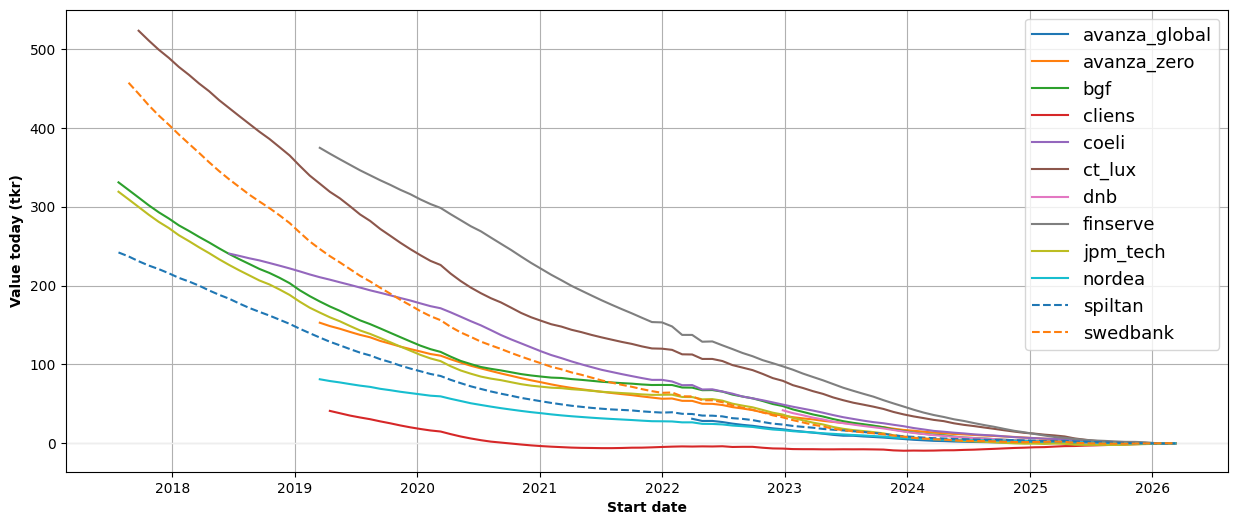

In [13]:
color_cycler = cycle(COLORS)
color_counter = Counter()
fig, ax = plt.subplots(1, 1, figsize=(15, 6))
for name, col in results["profit"].items():
    c = next(color_cycler)
    color_counter.update([c])
    linestyle = "--" if color_counter[c] > 1 else "-"
    ax.plot(
        col.dropna().index,
        col.dropna().values*1e-3,
        color=c,
        linestyle=linestyle,
        zorder=3,
        # lw=1,
        label=name,
    )
ax.grid(zorder=1)
ax.axhline(0, color="#eee", linewidth=1, zorder=2)
ax.legend(fontsize=13)
ax.set_ylabel("Value today (tkr)", fontweight="bold")
ax.set_xlabel("Start date", fontweight="bold")
plt.show()

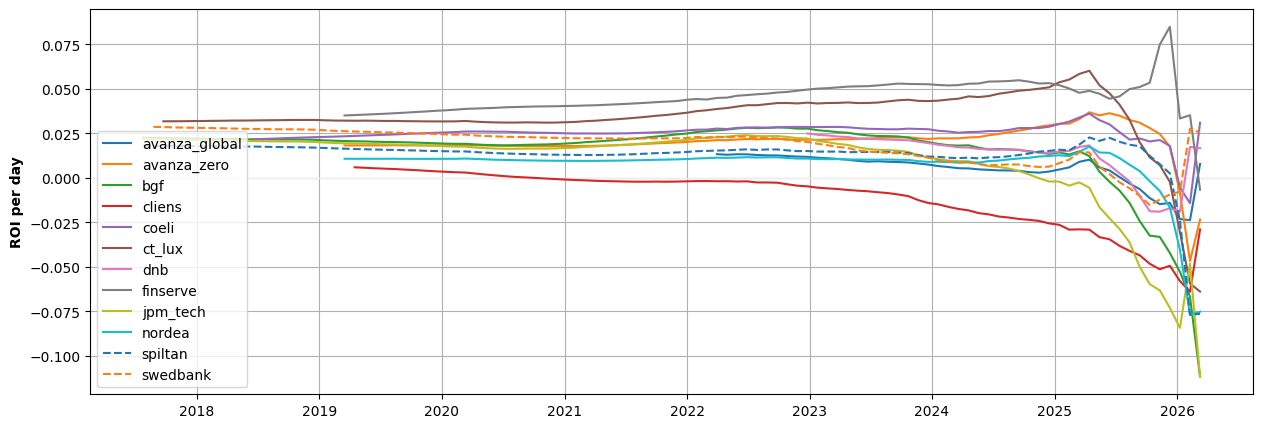

In [14]:
color_cycler = cycle(COLORS)
color_counter = Counter()

fig, ax = plt.subplots(1, 1, figsize=(15, 5))
for name in names:
    frame = results.xs(name, level="name", axis=1).dropna()
    frame = frame.assign(days=frame.index.diff().days.fillna(30).astype(int))
    frame = frame.assign(days=frame["days"].cumsum().values[::-1])
    frame = frame.assign(roi=1 + frame["profit"].div(frame["invested"]))
    frame = frame.assign(r_per_day=lambda x: 100 * (x["roi"].pow(1/x["days"]) - 1))

    c = next(color_cycler)
    color_counter.update([c])
    linestyle = "--" if color_counter[c] > 1 else "-"
    ax.plot(
        frame.index,
        frame["r_per_day"],
        zorder=3,
        label=name,
        color=c,
        linestyle=linestyle,
    )
ax.grid(zorder=1)
ax.axhline(0, color="#eee", linewidth=1, zorder=2)
ax.legend()
ax.set_ylabel("ROI per day", fontweight="bold")
plt.show()

In [15]:
def calc_rates(data):
    y = data.sort_values("date")["nav"].values.reshape(1, -1)
    y_inv = (1/y)
    R = y.T @ y_inv
    R = np.tril(R)
    R[R == 0] = np.nan
    return R

In [16]:
def calc_cagr(data):
    data = data.sort_values("date").copy()
    y = data["nav"].values.reshape(1, -1)

    x = data["date"].values
    X, Y = np.meshgrid(x.reshape(-1, 1), x.reshape(1, -1))
    Z = (Y - X).astype(int) * 1e-6 / 86400 / 365
    mask = Z > 0
    Z_inv = np.divide(1.0, Z, out=np.zeros_like(Z, dtype=float), where=(mask))

    y_inv = (1/y)
    R = y.T @ y_inv
    R = np.tril(R)
    R = R ** Z_inv
    R[~mask] = np.nan
    return R

In [17]:
arr = np.concatenate([r.flatten() for r in all_rates.values()])
arr = arr[~np.isnan(arr)]
arr = arr[arr < 1e1]


fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(
    arr,
    bins=1000,
    histtype="step",
    linewidth=2,
    cumulative=True,
    density=True,
    zorder=3,
)
ax.grid(zorder=1, which="both")
# ax.set_xscale("log")
ax.set_xlim(0, 2)
plt.show()

NameError: name 'all_rates' is not defined

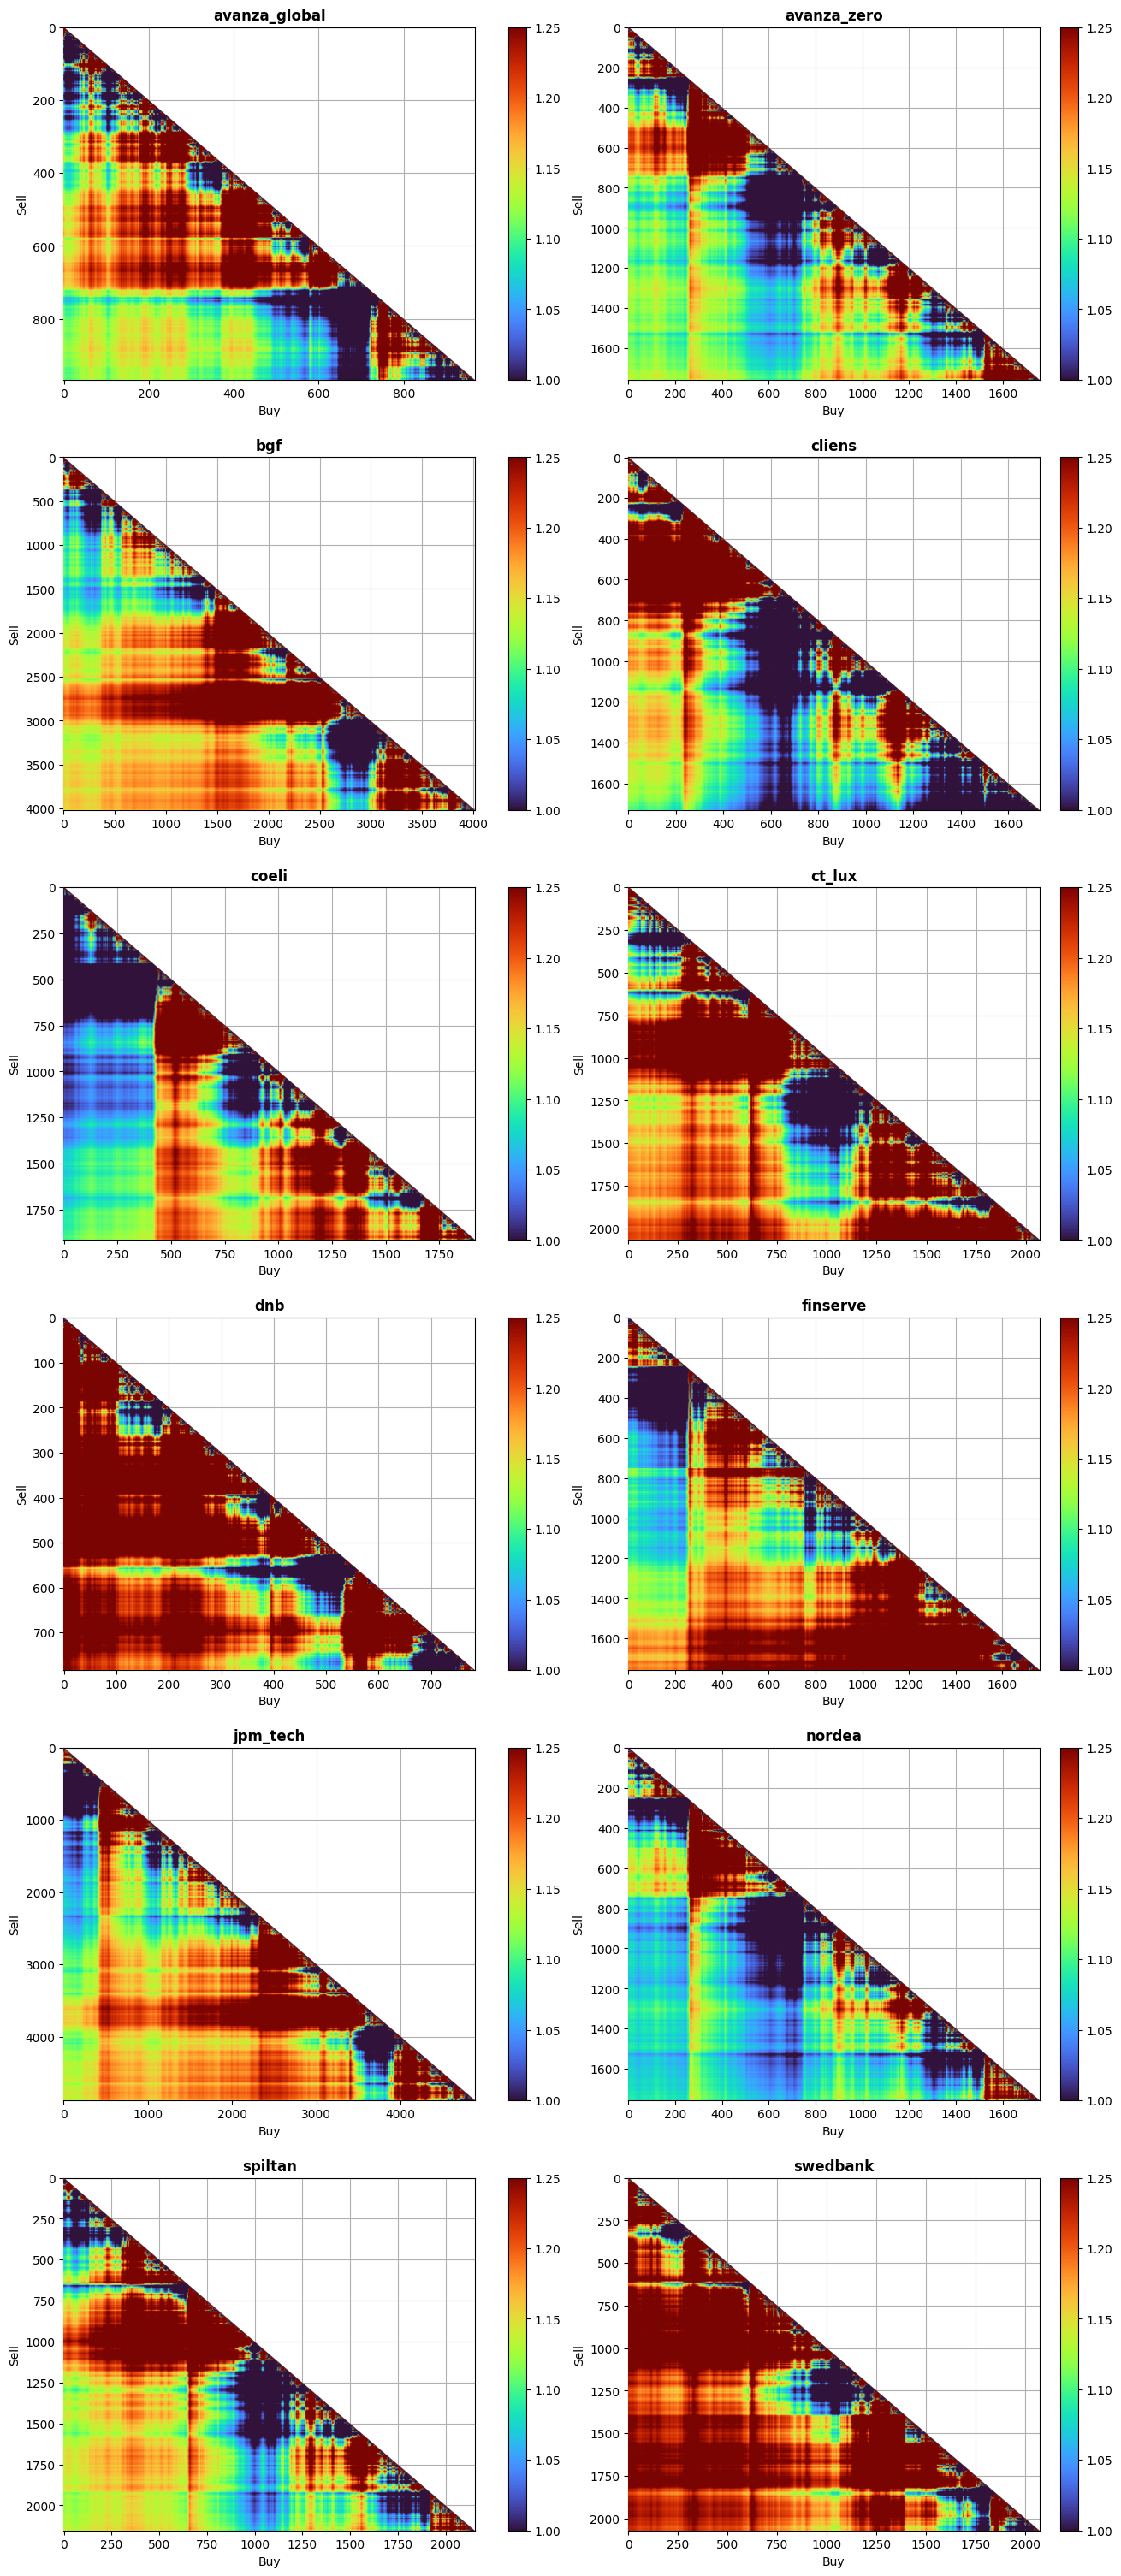

In [18]:
all_rates = {name: calc_cagr(df.query("name == @name").iloc[::1]) for name in names}

vmax = max([np.nanmax(r) for r in all_rates.values()])
vmin = max([np.nanmin(r) for r in all_rates.values()])
# norm = colors.TwoSlopeNorm(vmin=vmin, vcenter=1.0, vmax=min(5, vmax))
norm = colors.TwoSlopeNorm(vmin=0.8, vcenter=1.1, vmax=1.5)

ncols = 2
nrows = np.ceil(len(all_rates) / ncols).astype(int)
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(13, 5 * nrows),
    layout="constrained",
    gridspec_kw={"hspace": 0.05},
)
for ax, (name, R) in zip(axes.flatten(), all_rates.items()):
    # im = ax.imshow(np.log(R), aspect="auto", cmap="tab20b", vmin=-1, vmax=4, zorder=5)
    im = ax.imshow(
        R,
        aspect="auto",
        cmap="turbo",
        # norm=norm,
        vmin=1, vmax=1.25,
        zorder=5,
    )
    plt.colorbar(im, ax=ax)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Buy")
    ax.set_ylabel("Sell")
    ax.grid(zorder=1)
plt.show()

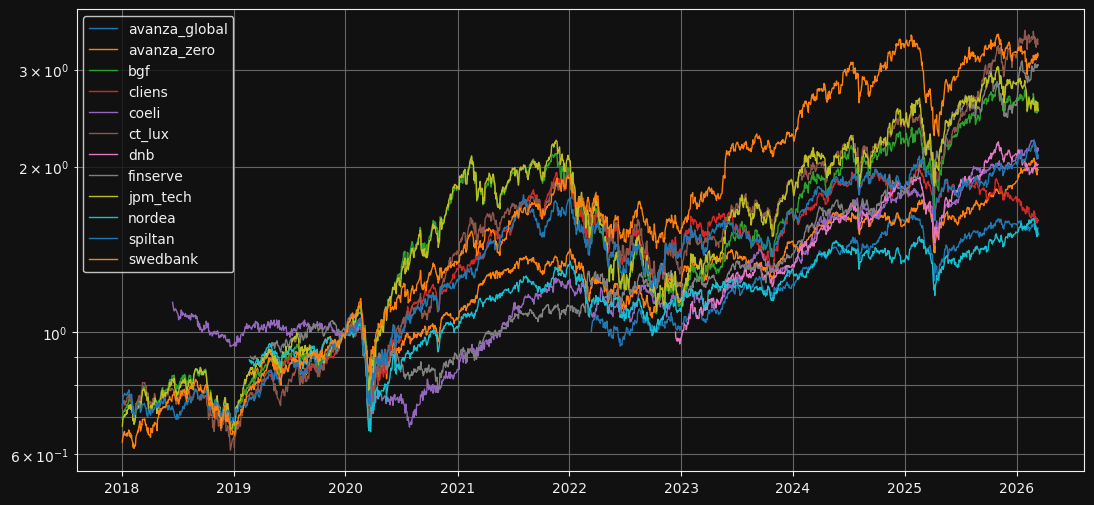

In [588]:
temp = df.pivot_table(index="date", columns="name", values="nav")
fig, ax = plt.subplots(figsize=(13, 6))
for name, col in temp.items():
    col = col.dropna()
    col = col.loc[col.index > datetime(2018, 1, 1)]
    norm = col.loc[col.index > datetime(2020, 1, 1)].iloc[0].item()
    ax.semilogy(col.index, col.values / norm, zorder=3, label=name, linewidth=1)
ax.grid(zorder=1, which="both")
ax.legend()
plt.show()